# Microwave resonator loss reconstruction
## Problem
Infer loaded, coupling and internal loss quality factors and resonance frequency from a measured full complex VNA sweep. The NIST-labelled resonator was measured on 2012-08-08 at nominal 275 mK and -90 dBm. The comparison is against an original-method reference, **not physical ground truth**.
## Data and Physics
The raw voltage transmission is $S(f)=a e^{i\alpha-2\pi i f\tau}[1-(Q_l/|Q_c|)e^{i\phi}/(1+2iQ_l(f-f_r)/f_r)]+\epsilon$. Frequency $f,f_r$ are Hz, delay $\tau$ is seconds, phases $\alpha,\phi$ are radians, gain $a$ and qualities are dimensionless. Complex coupling is $|Q_c|e^{-i\phi}$; diameter-corrected $Q_c=|Q_c|/\cos\phi$ and $Q_i^{-1}=Q_l^{-1}-Q_c^{-1}$.
## Method
Actively run the original published calibration/circle/phase algorithm extracted into local functions. A skewed Lorentzian initializes linewidth/frequency, linear phase initializes delay, iterative circle residuals refine delay, and off-resonance circle geometry determines gain/phase. Refit the normalized circle and staged periodic phase least squares; infer loss through diameter correction. No domain library or cached fit supplies the fresh output. The original native notebook's instrument/baseline examples are separate datasets; this notebook retains full raw/normalized-circle, phase, residual and corrected/uncorrected-loss comparisons for the bound measured sweep.

In [1]:
import os,sys,time,json,pathlib
import numpy as np
import matplotlib.pyplot as plt
task=pathlib.Path.cwd()
if task.name=='notebooks':task=task.parent
os.chdir(task);sys.path.insert(0,str(task))
from src.main import run
from src.preprocessing import load_data
from src.visualization import comparison
start=time.perf_counter()
fresh,fit,normalized,calibration=run()
runtime=time.perf_counter()-start
frequency,measured=load_data()
with np.load('notebooks/reference_outputs/upstream_original.npz',allow_pickle=False) as a:
    original={key:a[key].copy() for key in a.files}
print('Fresh complete reconstruction seconds:',runtime)
print('delay seconds, gain, phase rad, initializer fr, Ql, slope, frequency center:',calibration)
print('physical parameters:',fit)


Fresh complete reconstruction seconds: 0.010297799948602915
delay seconds, gain, phase rad, initializer fr, Ql, slope, frequency center: [4.40005072e-08 2.06921429e+00 2.84687782e+00 5.92251899e+09
 8.71291327e+04 0.00000000e+00 5.92251865e+09]
physical parameters: {'Qi_dia_corr': np.float64(127756.00296208196), 'Qi_no_corr': np.float64(127902.2147023118), 'absQc': np.float64(273317.60431328195), 'Qc_dia_corr': 273987.67635913135, 'Ql': np.float64(87129.11290017859), 'fr': np.float64(5922518993.515957), 'theta0': np.float64(-3.071640871448464), 'phi0': np.float64(0.06995178214132913), 'phi0_err': np.float64(0.012190368694798224), 'Ql_err': np.float64(823.7869748980518), 'absQc_err': np.float64(1122.0098453263265), 'fr_err': np.float64(458.8122462688606), 'chi_square': np.float64(7.343748879768608e-05), 'Qi_no_corr_err': np.float64(1714.6461190120976), 'Qi_dia_corr_err': np.float64(1711.4071916713567)}


## Results: observed data, reconstruction, original reference and residuals

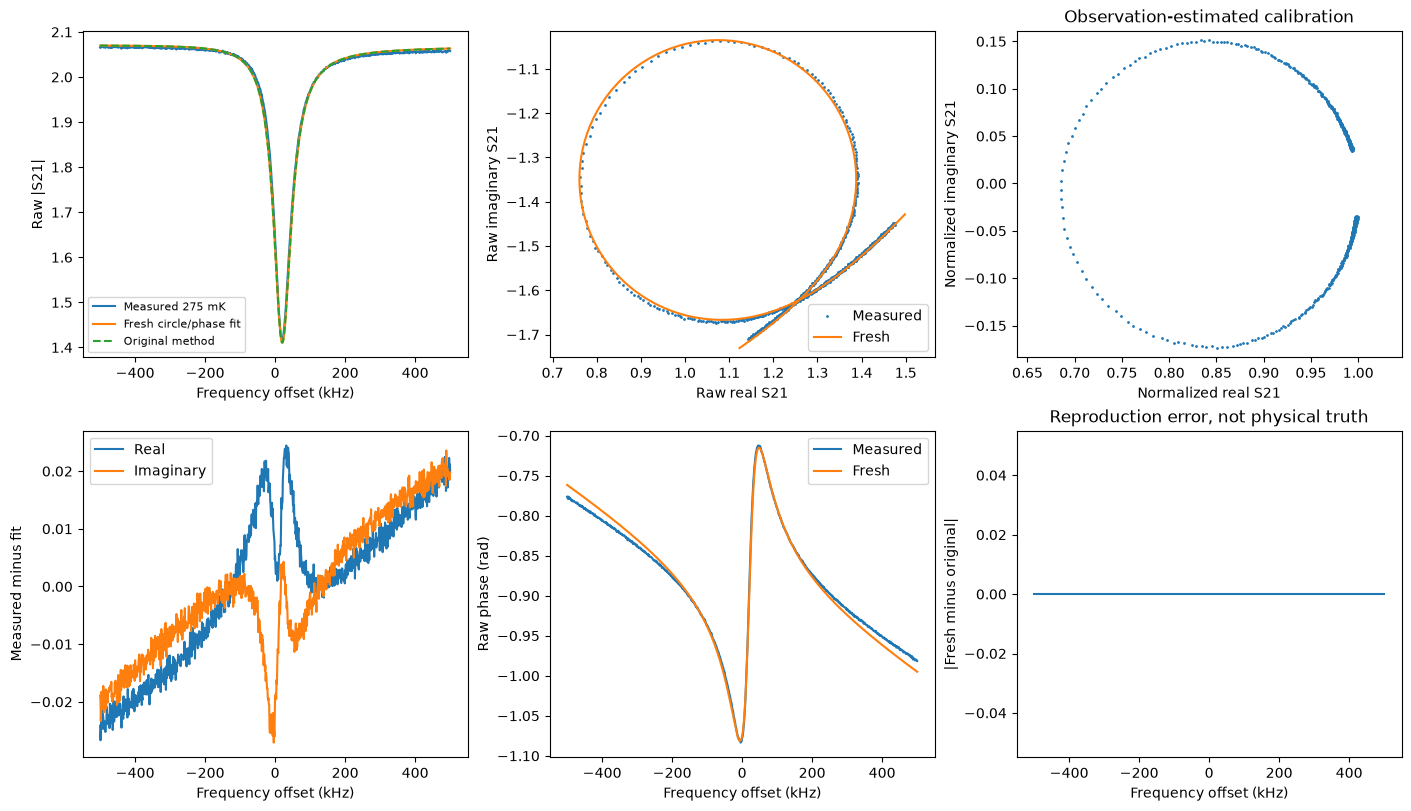

In [2]:
fig=comparison(frequency,measured,fresh['reconstruction'][0],original['z_sim'],normalized)
fig.savefig('notebooks/reference_outputs/reconstruction_review.png',dpi=140)
plt.show()


### Dissipation and uncertainty
Compare fresh diameter-corrected versus uncorrected internal quality and the original fit with its local covariance propagation. These are fit uncertainties conditional on the model, not independent metrological uncertainty. No perfectly known reference loss exists.

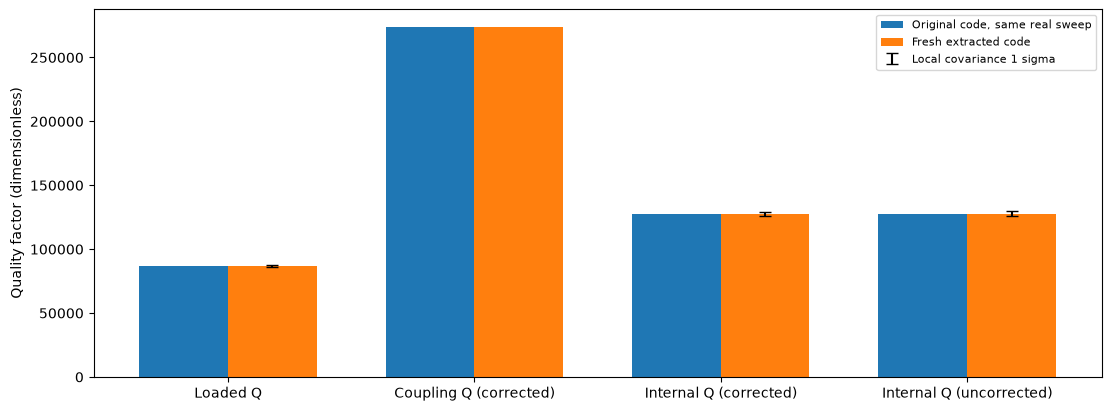

Loaded Q                       original=87129.1129002 fresh=87129.1129002
Coupling Q (corrected)         original=273987.676359 fresh=273987.676359
Internal Q (corrected)         original=127756.002962 fresh=127756.002962
Internal Q (uncorrected)       original=127902.214702 fresh=127902.214702
Inverse-Q conservation residual: 0.0


In [3]:
names=['Loaded Q','Coupling Q (corrected)','Internal Q (corrected)','Internal Q (uncorrected)']
values=np.array([fit['Ql'],fit['Qc_dia_corr'],fit['Qi_dia_corr'],fit['Qi_no_corr']])
original_values=np.array([float(original['fit_Ql']),float(original['fit_Qc_dia_corr']),float(original['fit_Qi_dia_corr']),float(original['fit_Qi_no_corr'])])
x=np.arange(4)
fig,ax=plt.subplots(figsize=(11,4),layout='constrained')
ax.bar(x-.18,original_values,width=.36,label='Original code, same real sweep')
ax.bar(x+.18,values,width=.36,label='Fresh extracted code')
ax.errorbar(x[[0,2,3]]+.18,values[[0,2,3]],yerr=[fit['Ql_err'],fit['Qi_dia_corr_err'],fit['Qi_no_corr_err']],fmt='none',color='black',capsize=4,label='Local covariance 1 sigma')
ax.set_xticks(x,names);ax.set_ylabel('Quality factor (dimensionless)');ax.legend(fontsize=8)
fig.savefig('notebooks/reference_outputs/loss_review.png',dpi=140)
plt.show()
for name,old,new in zip(names,original_values,values):print(f'{name:30s} original={old:.12g} fresh={new:.12g}')
print('Inverse-Q conservation residual:',1/values[0]-1/values[1]-1/values[2])


### Metrics and scientific calibration ablation

In [4]:
import importlib.util
spec=importlib.util.spec_from_file_location('judge','evaluation/judge.py')
judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
report,exitcode=judge.evaluate('output/reconstruction.npz')
assert exitcode==0,report
print(json.dumps(report,indent=2))
from src.physics_model import forward
uncalibrated=forward(frequency,fit['fr'],fit['Ql'],fit['absQc'],fit['phi0'])
metrics={'fresh_runtime_seconds':runtime,'original_response_difference':float(np.linalg.norm(fresh['reconstruction'][0]-original['z_sim'])),'uncalibrated_raw_relative_residual':float(np.linalg.norm(measured-uncalibrated)/np.linalg.norm(measured)),'calibrated_raw_relative_residual':float(np.linalg.norm(measured-fresh['reconstruction'][0])/np.linalg.norm(measured))}
print('Calibration ablation: same physical resonance, omit instrumental transfer:',metrics)
pathlib.Path('notebooks/reference_outputs/fresh_measurements.json').write_text(json.dumps(metrics,indent=2),encoding='utf8')


{
  "status": "pass",
  "passed": true,
  "metrics": {
    "frequency_relative_error": 0.0,
    "quality_factor_relative_error": 0.0,
    "complex_response_relative_l2_error": 0.0,
    "observation_relative_rms": 0.00879655899647674
  },
  "thresholds": {
    "frequency_relative_error": {
      "comparison": "<=",
      "boundary": 1e-07
    },
    "quality_factor_relative_error": {
      "comparison": "<=",
      "boundary": 0.0001
    },
    "complex_response_relative_l2_error": {
      "comparison": "<=",
      "boundary": 1e-05
    },
    "observation_relative_rms": {
      "comparison": "<=",
      "boundary": 0.009676214896124415
    }
  },
  "errors": []
}
Calibration ablation: same physical resonance, omit instrumental transfer: {'fresh_runtime_seconds': 0.010297799948602915, 'original_response_difference': 0.0, 'uncalibrated_raw_relative_residual': 0.7862401811236811, 'calibrated_raw_relative_residual': 0.00879655899647674}


209

### Supplemental experiment: sparse frequency sampling
Independently refit the same observed sweep retaining every 1, 2, 4 or 8 samples (1001,501,251,126 observations). This is an acquisition-density sensitivity experiment; the benchmark remains the complete1001-point sweep. Both the original author code and fresh extracted code perform full gain/phase/delay calibration for every subset. Adjacent instrument samples are not claimed independent noise draws. Compare changes to conditional full-sweep uncertainty rather than pretending the dense fit is physical truth.

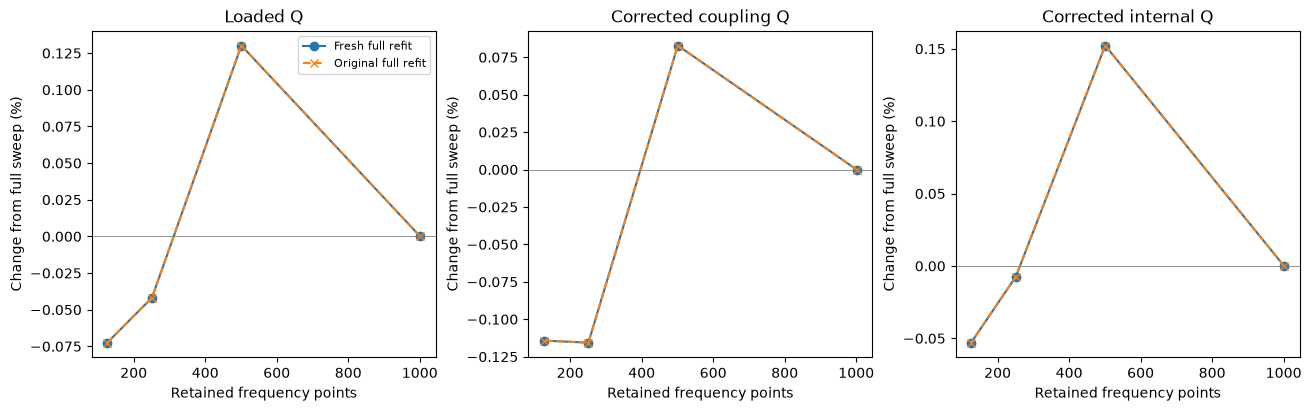

Columns: count, resonance Hz, Ql, Qc, Qi, delay seconds
[[1.00100000e+03 5.92251899e+09 8.71291129e+04 2.73987676e+05
  1.27756003e+05 4.40005072e-08]
 [5.01000000e+02 5.92251899e+09 8.72425341e+04 2.74214663e+05
  1.27950525e+05 4.39340534e-08]
 [2.51000000e+02 5.92251898e+09 8.70926903e+04 2.73670901e+05
  1.27746616e+05 4.40158145e-08]
 [1.26000000e+02 5.92251901e+09 8.70659821e+04 2.73674622e+05
  1.27688352e+05 4.40426666e-08]]
Maximum absolute internal-Q change (%): 0.1522607498979811
Full-sweep conditional internal-Q 1sigma (%): 1.339590431753961


In [5]:
from src.solvers import reconstruct
with np.load('notebooks/reference_outputs/upstream_subsampling.npz',allow_pickle=False) as a:
    strides=a['config_stride'];original_parameters=a['output_parameters']
fresh_parameters=[]
for stride in strides:
    subfit,subresponse,subnormalized,subcal=reconstruct(frequency[::stride],measured[::stride])
    fresh_parameters.append([subfit['fr'],subfit['Ql'],subfit['Qc_dia_corr'],subfit['Qi_dia_corr'],subcal[0]])
fresh_parameters=np.array(fresh_parameters)
np.testing.assert_allclose(fresh_parameters,original_parameters,rtol=1e-8,atol=1e-14)
fig,axs=plt.subplots(1,3,figsize=(13,4),layout='constrained')
count=np.array([frequency[::s].size for s in strides])
for ax,col,label in zip(axs,[1,2,3],['Loaded Q','Corrected coupling Q','Corrected internal Q']):
    ax.plot(count,100*(fresh_parameters[:,col]/fresh_parameters[0,col]-1),'o-',label='Fresh full refit')
    ax.plot(count,100*(original_parameters[:,col]/original_parameters[0,col]-1),'x--',label='Original full refit')
    ax.set(xlabel='Retained frequency points',ylabel='Change from full sweep (%)',title=label)
    ax.axhline(0,color='gray',lw=.6)
axs[0].legend(fontsize=8)
fig.savefig('notebooks/reference_outputs/subsampling_review.png',dpi=140)
plt.show()
print('Columns: count, resonance Hz, Ql, Qc, Qi, delay seconds')
print(np.column_stack([count,fresh_parameters]))
print('Maximum absolute internal-Q change (%):',100*np.max(np.abs(fresh_parameters[:,3]/fresh_parameters[0,3]-1)))
print('Full-sweep conditional internal-Q 1sigma (%):',100*fit['Qi_dia_corr_err']/fit['Qi_dia_corr'])
np.savez('notebooks/reference_outputs/fresh_subsampling.npz',count=count,parameters=fresh_parameters)


The sparse-sweep refits agree with independent original-code subset refits. Internal-Q changes stay below0.16%, compared with the full-sweep conditional covariance uncertainty of about1.34%. This demonstrates local sampling stability on this measured sweep, not immunity to correlated systematics or a general sparse-sampling guarantee. Structured residuals remain a separate model limitation.

## Conclusion
Fresh local calibration and full complex reconstruction reproduce the independently run original method. Gain/phase/delay removal is necessary for raw observation consistency. Diameter correction separates mismatch from dissipative coupling; its small effect in this dataset must not be generalized to stronger mismatch. Residuals and conditional covariance describe fit quality; agreement with the author method does not establish independently accurate material losses.